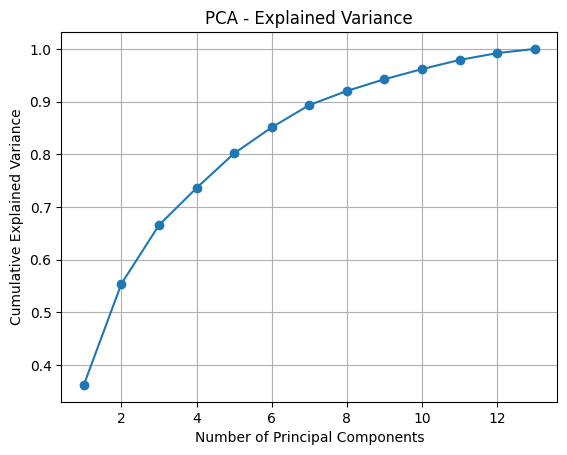

Original Dataset Shape: (178, 13)
Reduced Dataset Shape: (178, 2)
Explained Variance Ratio: [0.36198848 0.1920749 ]
Total Variance Retained: 0.5540633835693527


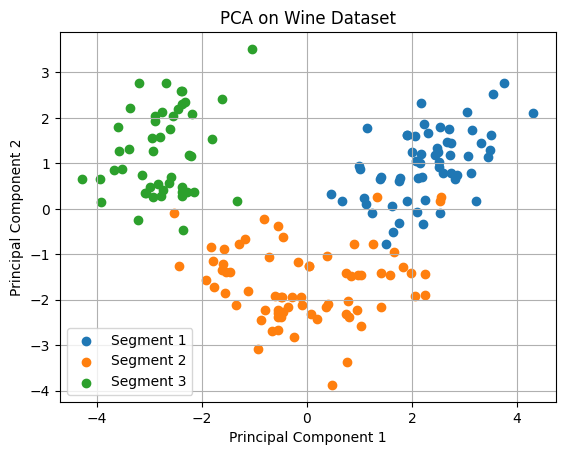

In [2]:
#1.Principal Component Analysis (PCA).ipynb
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# Load dataset
url = "https://media.geeksforgeeks.org/wp-content/uploads/Wine.csv"
df = pd.read_csv(url)

# Separate features and target
X = df.drop("Customer_Segment", axis=1)
y = df["Customer_Segment"]

# Standardize features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Apply PCA
pca = PCA()
X_pca = pca.fit_transform(X_scaled)

# Plot cumulative explained variance
variance = pca.explained_variance_ratio_
cumulative_variance = variance.cumsum()

plt.plot(range(1, len(variance) + 1),
         cumulative_variance, marker="o")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Explained Variance")
plt.grid(True)
plt.show()

# Reduce to two components
pca2 = PCA(n_components=2)
X_reduced = pca2.fit_transform(X_scaled)

# Display results
print("Original Dataset Shape:", X.shape)
print("Reduced Dataset Shape:", X_reduced.shape)
print("Explained Variance Ratio:",
      pca2.explained_variance_ratio_)
print("Total Variance Retained:",
      pca2.explained_variance_ratio_.sum())

# Visualize PCA results
for segment in sorted(y.unique()):
    idx = (y == segment).values
    plt.scatter(X_reduced[idx, 0],
                X_reduced[idx, 1],
                label=f"Segment {segment}")

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Wine Dataset")
plt.legend()
plt.grid(True)
plt.show()